# Going deeper with Convolutional Neural Networks (`main_report.ipynp`)

In [1]:
import torchvision.transforms as transforms
import torchvision
import torch.nn as nn
import torch.optim as optim
import torch

import numpy as np
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt


from tqdm import tqdm


torch.manual_seed(0)
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

transform = transforms.Compose(
    [transforms.Grayscale(),
     transforms.ToTensor(),
     transforms.Normalize((0.5), (0.5)),
    ])

trainval_dataset = torchvision.datasets.ImageFolder('chest_xray/trainval', transform = transform)
train_portion = 0.8
val_portion = 0.2

all_indexes = np.arange(len(trainval_dataset))
all_targets = trainval_dataset.targets

train_idx, val_idx = train_test_split(all_indexes, train_size=train_portion, stratify = all_targets, random_state = 0)

train_dataset = torch.utils.data.Subset(trainval_dataset, train_idx)
val_dataset = torch.utils.data.Subset(trainval_dataset, val_idx)

test_dataset = torchvision.datasets.ImageFolder('chest_xray/test', transform = transform)

batch_size = 16

trainloader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size,
                                          shuffle=True, num_workers = 2)
valloader = torch.utils.data.DataLoader(val_dataset, batch_size=batch_size,
                                          shuffle=False, num_workers = 2)
testloader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size,
                                          shuffle=False, num_workers = 2)


In [2]:
import os

# development.ipynb calibrates a decision threshold (P(PNEUMONIA) >= threshold)
# instead of the default 0.5 argmax boundary, and saves it next to vgg.pth so the
# Task 2 test-set metrics can be reproduced exactly from the saved model here.
if os.path.exists('threshold.txt'):
    with open('threshold.txt') as f:
        threshold = float(f.read())
else:
    threshold = 0.5
print(f"Using decision threshold: P(PNEUMONIA) >= {threshold:.2f}")


Using decision threshold: P(PNEUMONIA) >= 0.40


In [3]:
from model import load_vgg

vgg = load_vgg()
vgg.eval()
vgg.to(device)


VGG(
  (features): Sequential(
    (0): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU(inplace=True)
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU(inplace=True)
    (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (15): ReLU(inplace=True)
    (16): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1

Test set performance, classes: ['NORMAL', 'PNEUMONIA']
precision: [0.9364 0.9578]
recall: [0.9532 0.9425]


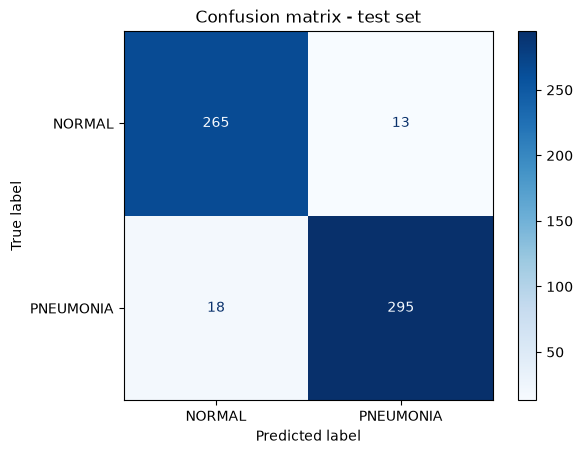

In [4]:
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix, ConfusionMatrixDisplay

vgg.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for inputs, labels in testloader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = vgg(inputs)
        probs = torch.softmax(outputs, dim=1)[:, 1]
        preds = (probs >= threshold).long()
        all_preds.append(preds.cpu().numpy())
        all_labels.append(labels.cpu().numpy())
all_preds = np.concatenate(all_preds)
all_labels = np.concatenate(all_labels)

precision, recall, _, _ = precision_recall_fscore_support(
    all_labels, all_preds, labels=[0, 1], zero_division=0)
print("Test set performance, classes:", test_dataset.classes)
print("precision:", precision.round(4))
print("recall:", recall.round(4))

# Confusion matrix for the report (question D)
cm = confusion_matrix(all_labels, all_preds, labels=[0, 1])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=test_dataset.classes)
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion matrix - test set")
plt.show()
